<a href="https://colab.research.google.com/github/kahrees/the-compendium/blob/main/Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Classical Machine Learning**

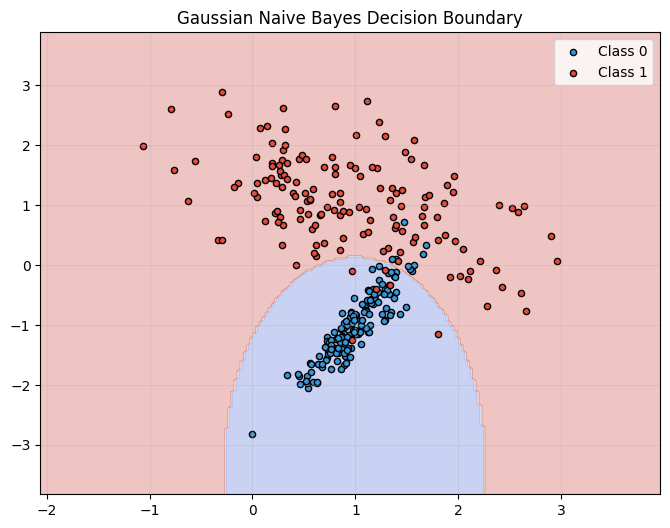

Training accuracy: 95.00%


In [1]:
import jax.numpy as jnp
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification

# Generate synthetic data
X, y = make_classification(n_samples=300, n_features=2, n_redundant=0,
                           n_informative=2, n_clusters_per_class=1, random_state=42)
X, y = jnp.array(X), jnp.array(y)

# Fit Gaussian Naive Bayes from scratch
classes = jnp.unique(y)
params = {}
for c in classes:
    c = int(c)
    mask = y == c
    X_c = X[mask]
    params[c] = {
        'mean': jnp.mean(X_c, axis=0),
        'var': jnp.var(X_c, axis=0),
        'prior': jnp.sum(mask) / len(y)
    }

def gaussian_log_likelihood(x, mean, var):
    return -0.5 * jnp.sum(jnp.log(2 * jnp.pi * var) + (x - mean)**2 / var)

def predict(X):
    preds = []
    for x in X:
        log_posts = []
        for c in [0, 1]:
            log_post = jnp.log(params[c]['prior']) + gaussian_log_likelihood(
                x, params[c]['mean'], params[c]['var'])
            log_posts.append(log_post)
        preds.append(jnp.argmax(jnp.array(log_posts)))
    return jnp.array(preds)

# Decision boundary visualisation
xx, yy = jnp.meshgrid(jnp.linspace(X[:,0].min()-1, X[:,0].max()+1, 200),
                       jnp.linspace(X[:,1].min()-1, X[:,1].max()+1, 200))
grid = jnp.column_stack([xx.ravel(), yy.ravel()])
zz = predict(grid).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, zz, alpha=0.3, cmap='coolwarm')
plt.scatter(X[y==0, 0], X[y==0, 1], c='#3498db', label='Class 0', edgecolors='k', s=20)
plt.scatter(X[y==1, 0], X[y==1, 1], c='#e74c3c', label='Class 1', edgecolors='k', s=20)
plt.title("Gaussian Naive Bayes Decision Boundary")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

accuracy = jnp.mean(predict(X) == y)
print(f"Training accuracy: {accuracy:.2%}")

In [2]:
def gini_impurity(y):
    """Gini impurity of a label array."""
    classes, counts = jnp.unique(y, return_counts=True)
    probs = counts / len(y)
    return 1.0 - jnp.sum(probs ** 2)

def information_gain(y, left_mask):
    """IG from splitting y into left/right by boolean mask."""
    parent_gini = gini_impurity(y)
    left_y, right_y = y[left_mask], y[~left_mask]
    n = len(y)
    if len(left_y) == 0 or len(right_y) == 0:
        return 0.0
    child_gini = (len(left_y)/n) * gini_impurity(left_y) + \
                 (len(right_y)/n) * gini_impurity(right_y)
    return float(parent_gini - child_gini)

def best_split(X, y):
    """Find the feature and threshold that maximise information gain."""
    best_ig, best_feat, best_thresh = -1, None, None
    for feat in range(X.shape[1]):
        thresholds = jnp.unique(X[:, feat])
        for thresh in thresholds:
            mask = X[:, feat] <= float(thresh)
            ig = information_gain(y, mask)
            if ig > best_ig:
                best_ig, best_feat, best_thresh = ig, feat, float(thresh)
    return best_feat, best_thresh, best_ig

# Example: synthetic data
from sklearn.datasets import make_classification
X, y = make_classification(n_samples=100, n_features=4, n_redundant=0, random_state=0)
X, y = jnp.array(X), jnp.array(y)

feat, thresh, ig = best_split(X, y)
print(f"Best split: feature {feat}, threshold {thresh:.3f}, info gain {ig:.4f}")
print(f"Parent Gini: {gini_impurity(y):.4f}")
mask = X[:, feat] <= thresh
print(f"Left Gini:   {gini_impurity(y[mask]):.4f} ({int(jnp.sum(mask))} samples)")
print(f"Right Gini:  {gini_impurity(y[~mask]):.4f} ({int(jnp.sum(~mask))} samples)")

Best split: feature 2, threshold -0.438, info gain 0.3533
Parent Gini: 0.4998
Left Gini:   0.1769 (51 samples)
Right Gini:  0.1150 (49 samples)
